In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
!pip install git+https://github.com/facebookresearch/segment-anything.git

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
  Cloning https://github.com/facebookresearch/segment-anything.git to /tmp/pip-req-build-5vjmd3mm
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/segment-anything.git /tmp/pip-req-build-5vjmd3mm
  Resolved https://github.com/facebookresearch/segment-anything.git to commit 3518c86b78b3bc9cf4fbe3d18e682fad1c79dc51
  Preparing metadata (setup.py) ... done
  Created wheel for segment-anything: filename=segment_anything-1.0-py3-none-any.whl size=36602 sha256=eb260f5297004a74f028b03f85b858ed64585bb5d2a015b6e788537472079739
  Stored in directory: /tmp/pip-ephem-wheel-cache-2p2kxttp/wheels/d5/11/03/7aca746a2c0e09f279b10436ced7175926bc38f650b736a648
Successfully built segment-anything


In [1]:
import os
import sys

# TODO: Fill in the Google Drive path where you uploaded the assignment
# Example: If you create a WI2022 folder and put all the files under A5 folder, then "WI2022/A5"
GOOGLE_DRIVE_PATH_AFTER_MYDRIVE = 'Wide Field Images Cropped'
GOOGLE_DRIVE_PATH = os.path.join("drive", "Shared drives", "M4AM", "Image Database",GOOGLE_DRIVE_PATH_AFTER_MYDRIVE)

#GOOGLE_DRIVE_PATH_AFTER_MYDRIVE_2 = 'EECS_598/A5'
#GOOGLE_DRIVE_PATH_2 = os.path.join("drive", "My Drive", GOOGLE_DRIVE_PATH_AFTER_MYDRIVE_2)

#GOOGLE_DRIVE_PATH_AFTER_MYDRIVE_2 = 'A5'
#GOOGLE_DRIVE_PATH_2 = os.path.join("drive", "My Drive", "EECS_598",GOOGLE_DRIVE_PATH_AFTER_MYDRIVE_2)

print(os.listdir(GOOGLE_DRIVE_PATH))


# Add to sys so we can import .py files.
sys.path.append(GOOGLE_DRIVE_PATH)

FileNotFoundError: [Errno 2] No such file or directory: 'drive/Shared drives/M4AM/Image Database/Wide Field Images Cropped'

In [ ]:
os.listdir(GOOGLE_DRIVE_PATH)[0][-3:]

'jpg'

In [2]:
import torchvision.transforms as T
from PIL import Image
import torch
from torchvision import transforms
from torchvision.utils import draw_segmentation_masks
import torchvision.transforms.functional as F

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import segment_anything
from segment_anything import SamPredictor, sam_model_registry, SamAutomaticMaskGenerator

In [3]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import cv2

In [4]:
if torch.cuda.is_available():
    print("Good to go!")
    DEVICE = torch.device("cuda")
else:
    print("Please set GPU via Edit -> Notebook Settings.")
    DEVICE = torch.device("cpu")

Please set GPU via Edit -> Notebook Settings.


In [5]:
sam = sam_model_registry["default"](checkpoint=os.path.join(GOOGLE_DRIVE_PATH, "sam_vit_h_4b8939.pth"))
sam.to(device=DEVICE)

FileNotFoundError: [Errno 2] No such file or directory: 'drive/Shared drives/M4AM/Image Database/Wide Field Images Cropped/sam_vit_h_4b8939.pth'

In [8]:
image = Image.open(os.path.join(GOOGLE_DRIVE_PATH, 'MEC_02_038_OPTIR_quartz_2.jpg'))
image = image.convert("RGB")
trans_img = T.Resize(size=224)(image)
transform = transforms.Compose([transforms.ToTensor()])
image_tensor = transform(image)
image_array = np.asarray(image)

In [9]:
images = [cv2.imread(os.path.join(GOOGLE_DRIVE_PATH, x)) if x[-3:] == 'jpg' else None 
          for x in os.listdir(GOOGLE_DRIVE_PATH)]
        
#image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

In [10]:
images = [cv2.cvtColor(image, cv2.COLOR_BGR2RGB) for image in images[:-4]]

In [11]:
images[0].shape

(609, 812, 3)

In [ ]:
plt.figure(figsize=(5,5))
for image in images:
  plt.imshow(image)
  plt.axis('off')
  plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
from tqdm import trange, tqdm

In [ ]:
mask_generator = SamAutomaticMaskGenerator(sam)
masks = []
for image in tqdm(images):
  masks.append(mask_generator.generate(image))

 94%|█████████▍| 17/18 [02:42<00:10, 10.28s/it]

In [ ]:
import pickle

file_name = "masks.pkl"
#open_file = open(file_name, "wb")
open_file = open(os.path.join(GOOGLE_DRIVE_PATH, file_name), "wb")
pickle.dump(masks, open_file)
open_file.close()

In [ ]:
import pickle

file_name = "masks.pkl"
open_file = open(os.path.join(GOOGLE_DRIVE_PATH, file_name), "rb")
masks = pickle.load(open_file)
open_file.close()

In [ ]:
def show_anns(anns):
    if len(anns) == 0:
        return
    sorted_anns = sorted(anns, key=(lambda x: x['area']), reverse=True)
    ax = plt.gca()
    ax.set_autoscale_on(False)
    polygons = []
    color = []
    for ann in sorted_anns:
        m = ann['segmentation']
        img = np.ones((m.shape[0], m.shape[1], 3))
        color_mask = np.random.random((1, 3)).tolist()[0]
        for i in range(3):
            img[:,:,i] = color_mask[i]
        ax.imshow(np.dstack((img, m*0.35)))

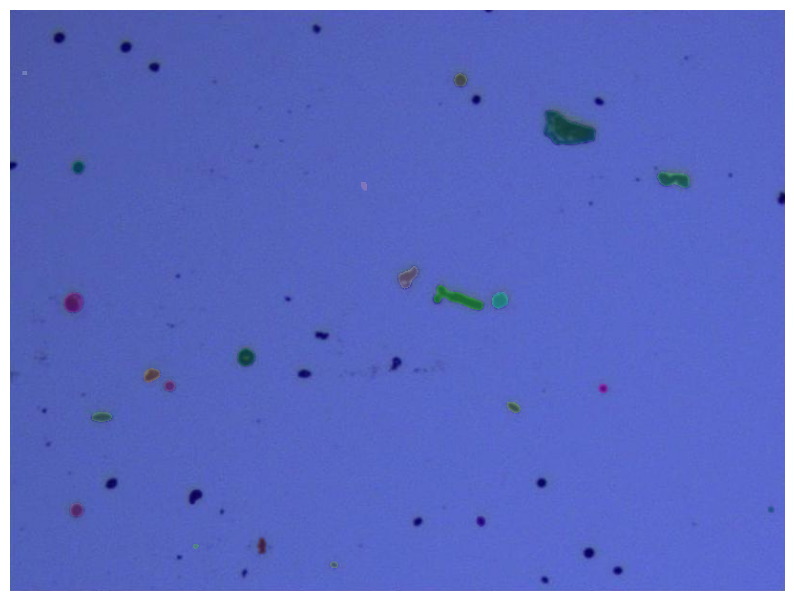

In [ ]:
plt.figure(figsize=(10,10))
plt.imshow(images[0])
show_anns(masks[0][1:])
plt.axis('off')
plt.show() 

In [ ]:
plt.figure(figsize=(5,5))
i=1
for image, mask in zip(images, masks):
  plt.imshow(image)
  show_anns(mask[1:])
  plt.axis('off')
  plt.savefig(os.path.join(GOOGLE_DRIVE_PATH, 'masks_segment_anything', 'image_'+str(i)+'.png'))
  plt.show() 
  i=i+1

Output hidden; open in https://colab.research.google.com to view.

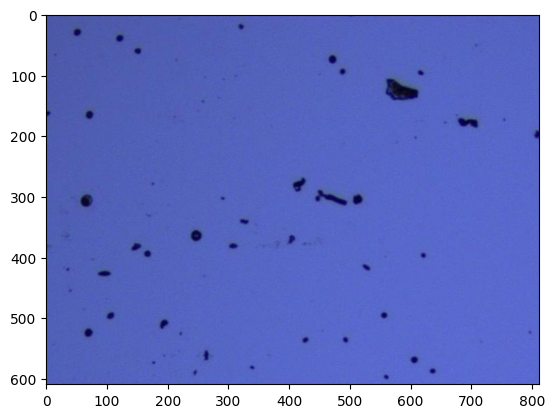

In [20]:
image = images[0]
plt.imshow(image)
#grayscale = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
#cv2.imshow('Grayscale', grayscale)

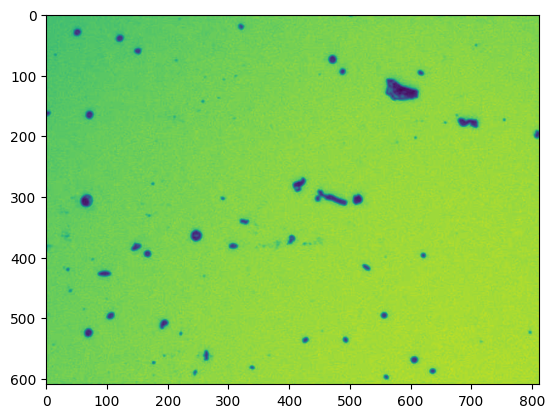

In [21]:
grayscale = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(grayscale)

(array([5.47000e+02, 1.62000e+03, 1.36700e+03, 9.70000e+02, 9.84000e+02,
        1.08600e+03, 3.40200e+03, 1.49871e+05, 3.34407e+05, 2.54000e+02]),
 array([  8. ,  22.5,  37. ,  51.5,  66. ,  80.5,  95. , 109.5, 124. ,
        138.5, 153. ]),
 <BarContainer object of 10 artists>)

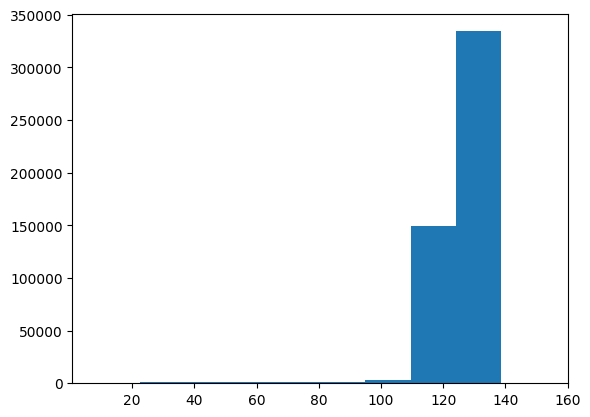

In [28]:
plt.hist(grayscale.flatten())

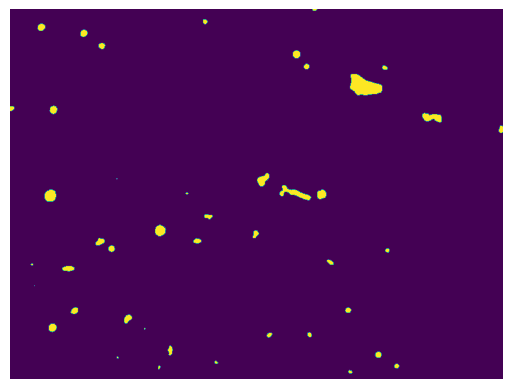

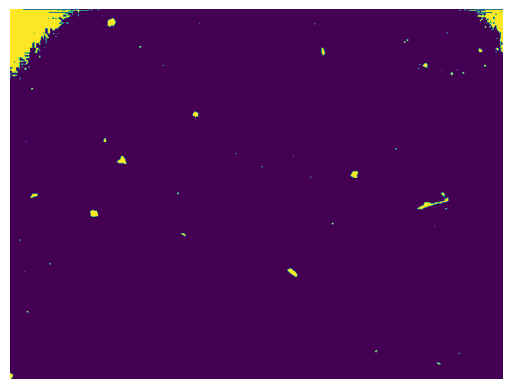

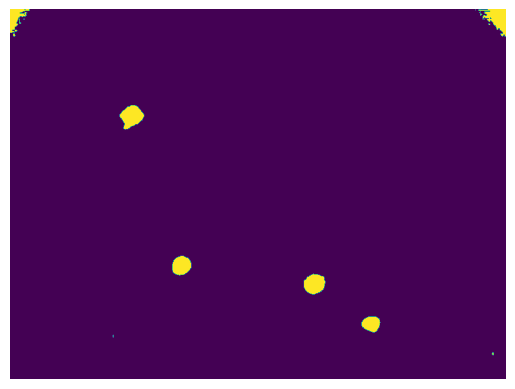

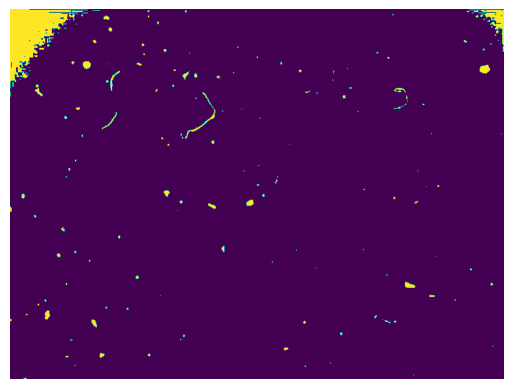

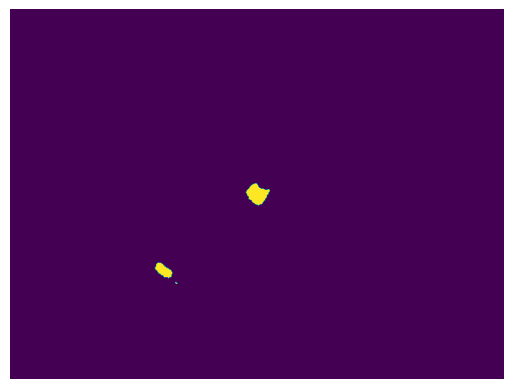

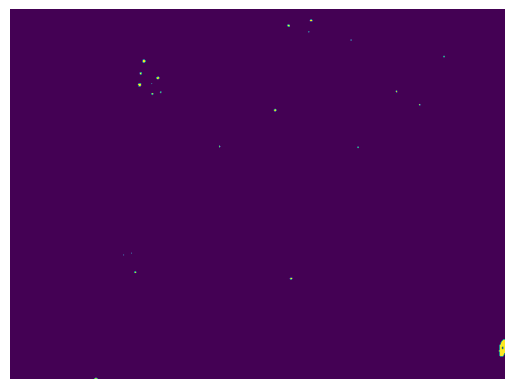

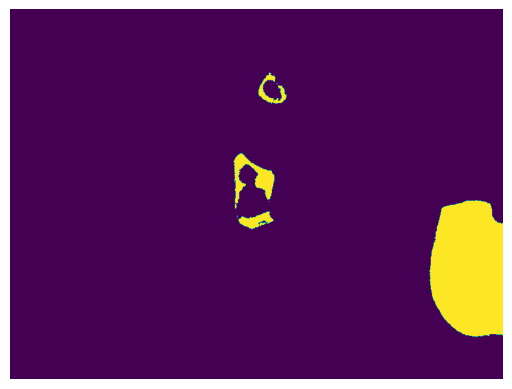

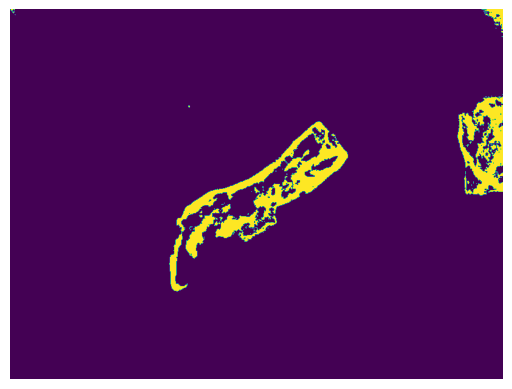

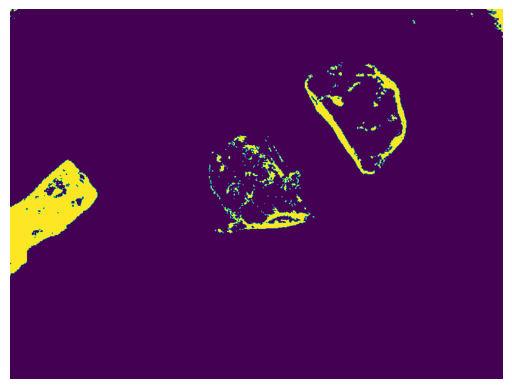

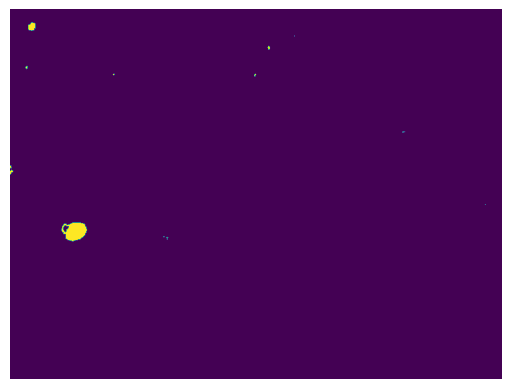

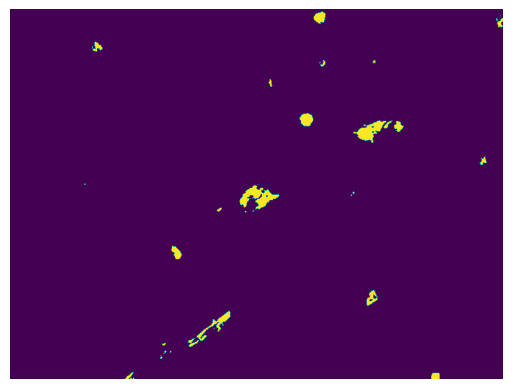

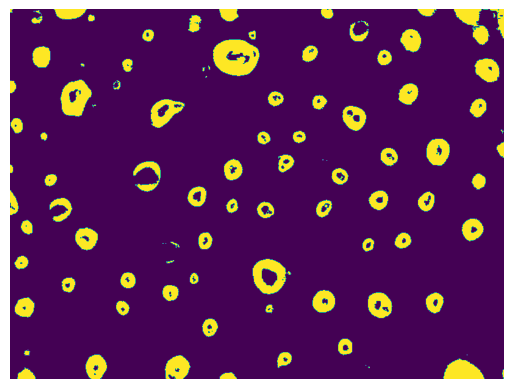

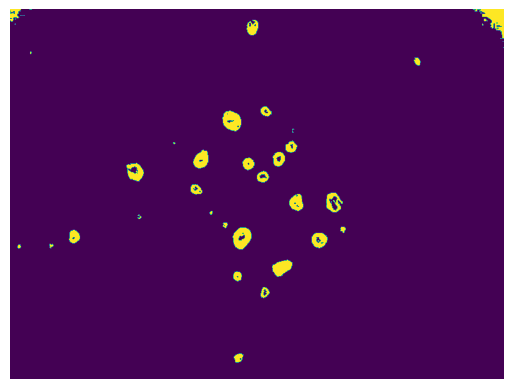

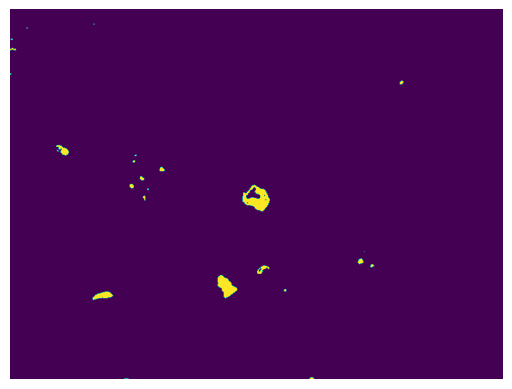

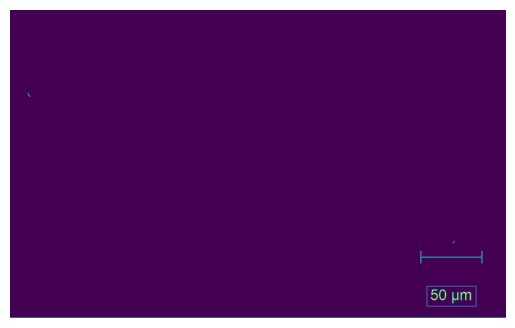

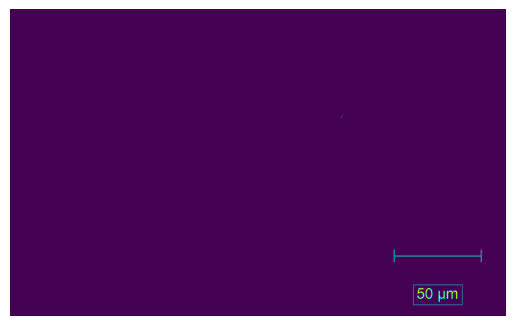

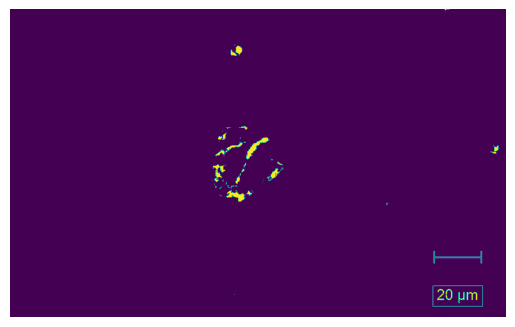

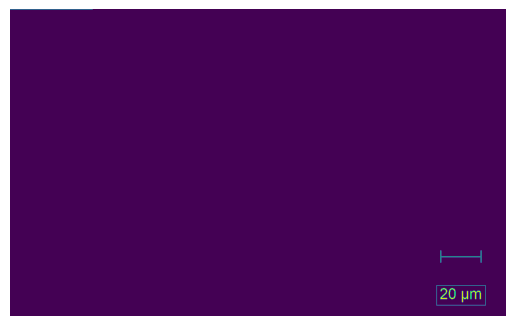

In [66]:
low = np.array([0])
high = np.array([80])

for image in images:
  grayscale = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
  mask = cv2.inRange(grayscale, low, high)

  plt.axis('off')
  plt.imshow(mask)

  result = cv2.bitwise_and(image, image, mask=255 - mask)

  #plt.imshow(result)
  
  plt.show()

In [58]:
255 - mask //2 

array([[255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       ...,
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255]], dtype=uint8)

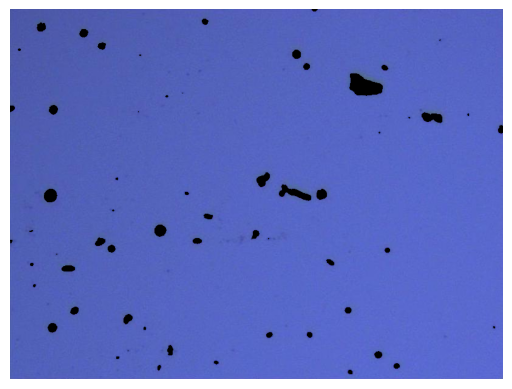

In [61]:
result = cv2.bitwise_and(image, image, mask=255 - mask)

plt.axis('off')
plt.imshow(result)